## 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading Cleaned Dataset

In [2]:
df = pd.read_csv(r'C:\Users\BIT\OneDrive\Desktop\Yash\Projects\IIIT Internship Project\Dataset\student_performance_cleaned.csv')
print("Shape:", df.shape)
df.head()

Shape: (12469, 19)


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade,PerformanceIndex,EngagementScore,RiskCategory
0,19,64,1,No,Low,Yes,Male,19,Reading/Writing,8,1,59,40,Low,Medium,D,51.0,5.2,High Risk
1,19,64,1,No,Low,Yes,Male,23,Kinesthetic,16,0,90,66,Low,Medium,C,70.2,9.6,Medium Risk
2,19,64,1,No,Low,Yes,Male,28,Auditory,19,0,67,99,High,Medium,A,82.1,11.4,Low Risk
3,19,64,1,Yes,Low,Yes,Male,19,Reading/Writing,8,1,59,40,Low,Medium,D,51.0,5.2,High Risk
4,19,64,1,Yes,Low,Yes,Male,23,Kinesthetic,16,0,90,66,Low,Medium,C,70.2,9.6,Medium Risk


## 3. Statistical Analysis

### 3.1 Correlation Analysis

In [3]:
correlation_matrix = df.select_dtypes(include=[np.number]).corr()
print(correlation_matrix['PerformanceIndex'].sort_values(ascending=False))

PerformanceIndex        1.000000
ExamScore               0.891358
Attendance              0.332244
AssignmentCompletion    0.317949
OnlineCourses           0.023879
EngagementScore         0.022263
StudyHours              0.016065
Resources              -0.000649
Age                    -0.027494
Discussions            -0.029708
Name: PerformanceIndex, dtype: float64


### 3.2 ANOVA Test

In [4]:
# Group PerformanceIndex by StressLevel

low = df[df['StressLevel'] == 'Low']['PerformanceIndex']
medium = df[df['StressLevel'] == 'Medium']['PerformanceIndex']
high = df[df['StressLevel'] == 'High']['PerformanceIndex']

f_stat, p_value = stats.f_oneway(low, medium, high)

print("F_Statistic:", f_stat)
print("p_value:", p_value)

F_Statistic: 10.86849662812691
p_value: 1.923013616551939e-05


In [5]:
# Motivation vs PerformanceIndex

low_m = df[df['Motivation'] == 'Low']['PerformanceIndex']
med_m = df[df['Motivation'] == 'Medium']['PerformanceIndex']
high_m = df[df['Motivation'] == 'High']['PerformanceIndex']

f_stat_m, p_value_m = stats.f_oneway(low_m, med_m, high_m)
print("Motivation -> F-statistic:", f_stat_m, "| p-value:", p_value_m)

Motivation -> F-statistic: 0.9451484895469088 | p-value: 0.3886497069093229


In [6]:
# Learning Style vs PerformanceIndex

visual = df[df['LearningStyle'] == 'Visual']['PerformanceIndex']
auditory = df[df['LearningStyle'] == 'Auditory']['PerformanceIndex']
reading = df[df['LearningStyle'] == 'Reading/Writing']['PerformanceIndex']
kinesthetic = df[df['LearningStyle'] == 'Kinesthetic']['PerformanceIndex']

f_stat_l, p_value_l = stats.f_oneway(visual, auditory, reading, kinesthetic)
print("Learning Style -> F-statistic:", f_stat_l, "| p-value:", p_value_l)

Learning Style -> F-statistic: 0.9654441103756298 | p-value: 0.40792154924311885


### 3.3 Chi-Square Test

In [7]:
# Gender vs RiskCategory

contingency_table = pd.crosstab(df['Gender'], df['RiskCategory'])
print(contingency_table)

chi2, p_val, dof, expected = stats.chi2_contingency(contingency_table)
print("\nChi2 statistic:", chi2)
print("p-value:", p_val)
print("Degrees of freedom:", dof)

RiskCategory  High Risk  Low Risk  Medium Risk
Gender                                        
Female              522      2126         4068
Male                464      1721         3568

Chi2 statistic: 4.44106100998508
p-value: 0.10855150643102077
Degrees of freedom: 2


## 4. Machine Learning - Risk Category Prediction

### 4.1 Data Preparation & Encoding

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Making a copy for ML so we don't disturb the original df
ml_df = df.copy()

# Encoding categorical columns
categorical_cols = ['Gender', 'Internet', 'Extracurricular', 'EduTech', 'Motivation', 'StressLevel', 'LearningStyle']

encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    ml_df[col] = le.fit_transform(ml_df[col])
    encoders[col] = le

# Encoding target variable
target_encoder = LabelEncoder()
ml_df['RiskCategory'] = target_encoder.fit_transform(ml_df['RiskCategory'])

print("RiskCategory classes:", target_encoder.classes_)
print("Encoded as:", target_encoder.transform(target_encoder.classes_))

RiskCategory classes: ['High Risk' 'Low Risk' 'Medium Risk']
Encoded as: [0 1 2]


### 4.2 Data Leakage Check

In [9]:
# Checking if RiskCategory is derived from features we're using
# (i.e. checking for data leakage before trusting any model results)

print("PerformanceIndex by RiskCategory:")
print(df.groupby('RiskCategory')['PerformanceIndex'].agg(['min', 'max', 'mean']))

print("\nExamScore by RiskCategory:")
print(df.groupby('RiskCategory')['ExamScore'].agg(['min', 'max', 'mean']))

print("\nAttendance by RiskCategory:")
print(df.groupby('RiskCategory')['Attendance'].agg(['min', 'max', 'mean']))

print("\nAssignmentCompletion by RiskCategory:")
print(df.groupby('RiskCategory')['AssignmentCompletion'].agg(['min', 'max', 'mean']))

print("\nEngagementScore by RiskCategory:")
print(df.groupby('RiskCategory')['EngagementScore'].agg(['min', 'max', 'mean']))

PerformanceIndex by RiskCategory:
               min   max       mean
RiskCategory                       
High Risk     48.0  60.0  56.800507
Low Risk      80.0  98.8  85.888900
Medium Risk   60.0  79.9  70.443871

ExamScore by RiskCategory:
              min  max       mean
RiskCategory                     
High Risk      40   60  45.330629
Low Risk       63  100  89.383676
Medium Risk    40  100  63.927318

Attendance by RiskCategory:
              min  max       mean
RiskCategory                     
High Risk      60   94  70.936105
Low Risk       60  100  84.208734
Medium Risk    60  100  79.440676

AssignmentCompletion by RiskCategory:
              min  max       mean
RiskCategory                     
High Risk      50   99  64.271805
Low Risk       50  100  79.672212
Medium Risk    50  100  73.240047

EngagementScore by RiskCategory:
              min   max      mean
RiskCategory                     
High Risk     0.0  12.4  6.024949
Low Risk      0.0  12.4  6.203587
Medium Ris

### 4.3 Train-Test Split

In [10]:
# Define features(X) and target(Y)
feature_cols = ['Age', 'Gender', 'StudyHours', 'Discussions', 'Motivation', 
                 'StressLevel', 'Internet', 'OnlineCourses', 'Extracurricular', 
                 'EduTech', 'EngagementScore']

X = ml_df[feature_cols]
y = ml_df['RiskCategory']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)

Training set size: (9975, 11)
Test set size: (2494, 11)


### 4.4 Model Training (Random Forest)

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### 4.5 Model Evaluation

In [12]:
# Predict on test set
y_pred = rf_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print(f"Model Accuracy: {accuracy:.2%}")

# Deatiled report (precision, recall, F1 for each class)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names = target_encoder.classes_))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

Accuracy: 0.8484362469927826
Model Accuracy: 84.84%

Classification Report:
              precision    recall  f1-score   support

   High Risk       0.88      0.53      0.66       184
    Low Risk       0.87      0.72      0.79       768
 Medium Risk       0.84      0.95      0.89      1542

    accuracy                           0.85      2494
   macro avg       0.86      0.73      0.78      2494
weighted avg       0.85      0.85      0.84      2494


Confusion Matrix:
[[  97   12   75]
 [   4  554  210]
 [   9   68 1465]]


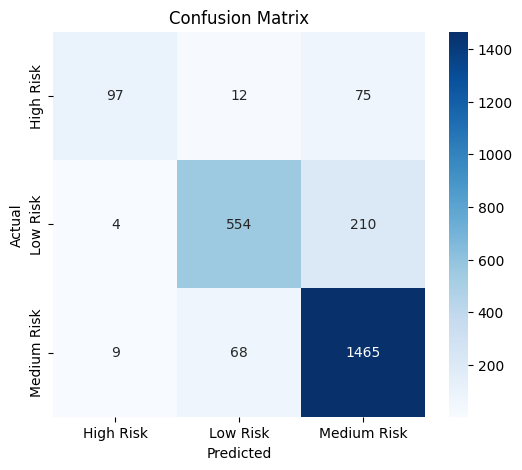

In [13]:
# Visualizing Confusion Matrix

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', xticklabels = target_encoder.classes_, yticklabels = target_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### 4.6 Feature Importance Analysis

In [14]:
# Identifying the most influential factors affecting risk category prediction.

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by = 'Importance', ascending = False)

print(feature_importance)

            Feature  Importance
2        StudyHours    0.266504
0               Age    0.198466
10  EngagementScore    0.134204
7     OnlineCourses    0.122859
5       StressLevel    0.071262
4        Motivation    0.053539
1            Gender    0.048193
9           EduTech    0.037625
8   Extracurricular    0.033457
3       Discussions    0.016997
6          Internet    0.016895


C:\Users\BIT\AppData\Local\Temp\ipykernel_11940\636275806.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance, x='Importance', y='Feature', palette='viridis')


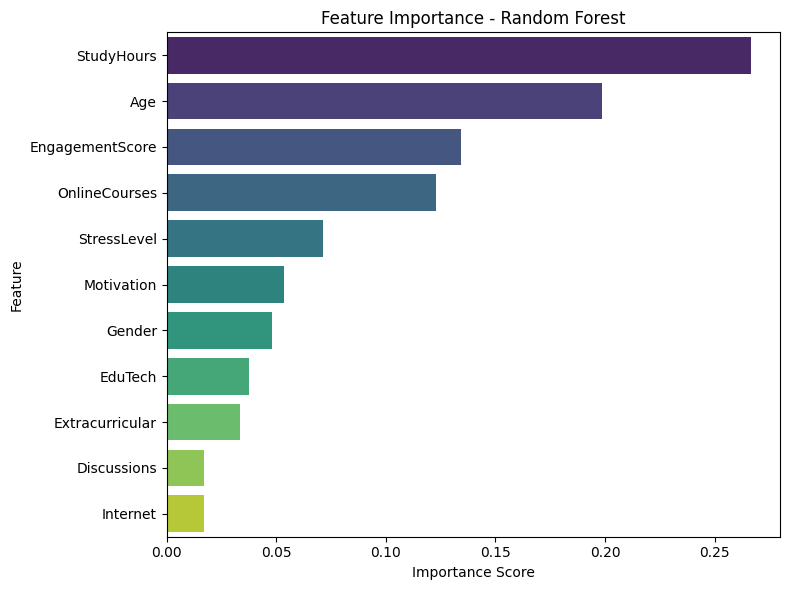

In [15]:
# Visualizing feature importance as a bar chart

plt.figure(figsize=(8, 6))
sns.barplot(data=feature_importance, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 5. Exporting Predictions for Power BI

In [16]:
# Creating a results dataframe with actual vs predicted risk categories

results_df = X_test.copy()
results_df['Actual_RiskCategory'] = target_encoder.inverse_transform(y_test)
results_df['Predicted_RiskCategory'] = target_encoder.inverse_transform(y_pred)
results_df['Correct_Prediction'] = results_df['Actual_RiskCategory'] == results_df['Predicted_RiskCategory']

results_df.head()

,Age,Gender,StudyHours,Discussions,Motivation,StressLevel,Internet,OnlineCourses,Extracurricular,EduTech,EngagementScore,Actual_RiskCategory,Predicted_RiskCategory,Correct_Prediction
3282,28,1,11,0,2,1,1,4,0,1,2.4,Medium Risk,Medium Risk,True
11925,21,0,18,1,1,0,1,5,0,0,3.4,Medium Risk,Low Risk,False
9349,28,0,5,1,2,0,1,2,1,0,1.6,Medium Risk,Medium Risk,True
8509,20,0,18,1,1,2,1,4,1,0,2.8,High Risk,Medium Risk,False
7498,29,1,24,1,2,1,1,2,0,1,1.6,Low Risk,Low Risk,True


In [17]:
# Saving predictions as a new csv file.

results_df.to_csv(r"C:\Users\BIT\OneDrive\Desktop\Yash\Projects\IIIT Internship Project\Dataset\model_predictions.csv", index=False)

print("Predictions exported successfully")

Predictions exported successfully


In [18]:
feature_importance.to_csv(
    r"C:\Users\BIT\OneDrive\Desktop\Yash\Projects\IIIT Internship Project\Dataset\feature_importance.csv",
    index=False
)
print("Feature importance exported successfully")

Feature importance exported successfully
